# Descripción del proyecto

La compañía Sweet Lift Taxi ha recopilado datos históricos sobre pedidos de taxis en los aeropuertos. Para atraer a más conductores durante las horas pico, necesitamos predecir la cantidad de pedidos de taxis para la próxima hora. Construye un modelo para dicha predicción.

La métrica RECM en el conjunto de prueba no debe ser superior a 48.

## Instrucciones del proyecto.

1. Descarga los datos y haz el remuestreo por una hora.
2. Analiza los datos
3. Entrena diferentes modelos con diferentes hiperparámetros. La muestra de prueba debe ser el 10% del conjunto de datos inicial.4. Prueba los datos usando la muestra de prueba y proporciona una conclusión.

## Descripción de los datos

Los datos se almacenan en el archivo `taxi.csv`. 	
El número de pedidos está en la columna `num_orders`.

## Preparación

In [19]:
# Descarga librerias requeridas para el proyecto
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose
from sklearn.model_selection import train_test_split, TimeSeriesSplit, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error

# Definición de random_state
rnd_stt = 792604

# Carga de datos
data = pd.read_csv('/datasets/taxi.csv', index_col=[0], parse_dates=[0])
print(data.info())

data.head()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 26496 entries, 2018-03-01 00:00:00 to 2018-08-31 23:50:00
Data columns (total 1 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   num_orders  26496 non-null  int64
dtypes: int64(1)
memory usage: 414.0 KB
None


,num_orders
datetime,
2018-03-01 00:00:00,9
2018-03-01 00:10:00,14
2018-03-01 00:20:00,28
2018-03-01 00:30:00,20
2018-03-01 00:40:00,32


#### Observaciones

El archivo **taxis.csv** tiene 26496 observaciones y solo la columna de ordenes recibidas. tiene un intervalo de tiempo de 10 minutos y se encuentra ordenado de forma cronológica.

In [2]:
# Información relevante del dataset
print('El índice esta ordenado? ', data.index.is_monotonic_increasing)
print('Valores ausentes: ', data.isna().sum())
print('Datos duplicados: ', data.index.duplicated().sum())
print('Rango de fechas del dataset: ', data.index.min(), data.index.max())
print('Diferencias entre timestamps consecutivos')
print(data.index.to_series().diff().value_counts())


El índice esta ordenado?  True
Valores ausentes:  num_orders    0
dtype: int64
Datos duplicados:  0
Rango de fechas del dataset:  2018-03-01 00:00:00 2018-08-31 23:50:00
Diferencias entre timestamps consecutivos
0 days 00:10:00    26495
Name: datetime, dtype: int64


#### Observaciones
Se revisa el juego de datos con precaución y se encuentra lo siguiente:
- El juego de datos se encuentra ordenado cronológicamente.
- El juego de datos no tiene datos ausentes.
- El juego de datos no tiene datos duplicados en cuanto a marcas de tiempo.
- Se tiene un intérvalo de datos entre el 1 de marzo y el 31 de agosto de 2018.
- Los datos no tienen brechas de tiempo diferentes a 10 minutos. Esto nos permitirá realizar un remuestreo fácil sin tener que adicionar valores faltantes. El juego de datos es robusto en su información.

El objetivo del proyecto es encontrar un modelo que prediga el número de pedidos de taxi *por hora*. Por ello, se debe realizar un remuestreo por hora, y sumando el número de pedidos dentro del remuestreo.



In [3]:
# Remuestreo de los datos
data.sort_index(inplace=True)
data = data.resample('1h').sum()

# Forma final dataset
print(data.shape)
data.head()

(4416, 1)


,num_orders
datetime,
2018-03-01 00:00:00,124
2018-03-01 01:00:00,85
2018-03-01 02:00:00,71
2018-03-01 03:00:00,66
2018-03-01 04:00:00,43


#### Observaciones
Se ha ejecutado exitosamente el remuestreo de los datos ajustados en intérvalos de 1 hora y se cuenta ahora con 4416 observaciones para desarrollar el modelo.

## Análisis

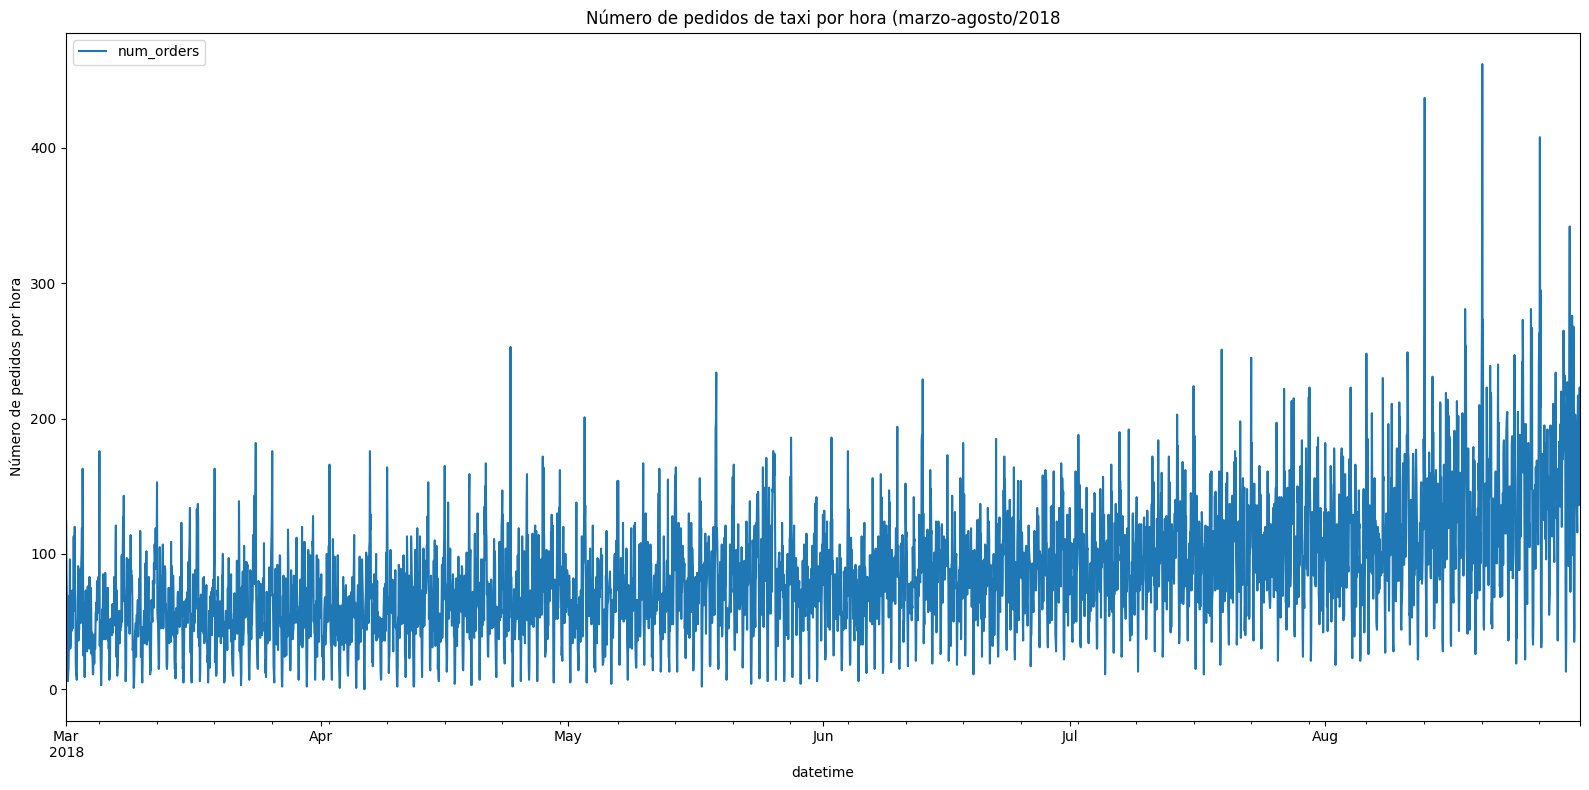

In [4]:
# Gráfico de comportamiento de los datos
data.plot(figsize=(16,8), title='Número de pedidos de taxi por hora (marzo-agosto/2018')
plt.ylabel('Número de pedidos por hora')
plt.tight_layout()
plt.show()

#### Observaciones
Se identifica una tendencia incremental en el periodo disponible en el pedido de taxis por hora, con una variación que puede considerarse inicialmente como estacionalidad, la cual puede estar relacionada con el día de la semana.
Se debe hacer la descomposición del juego de datos para identificar *tendencia*, *estacionalidad* y *residuos*.

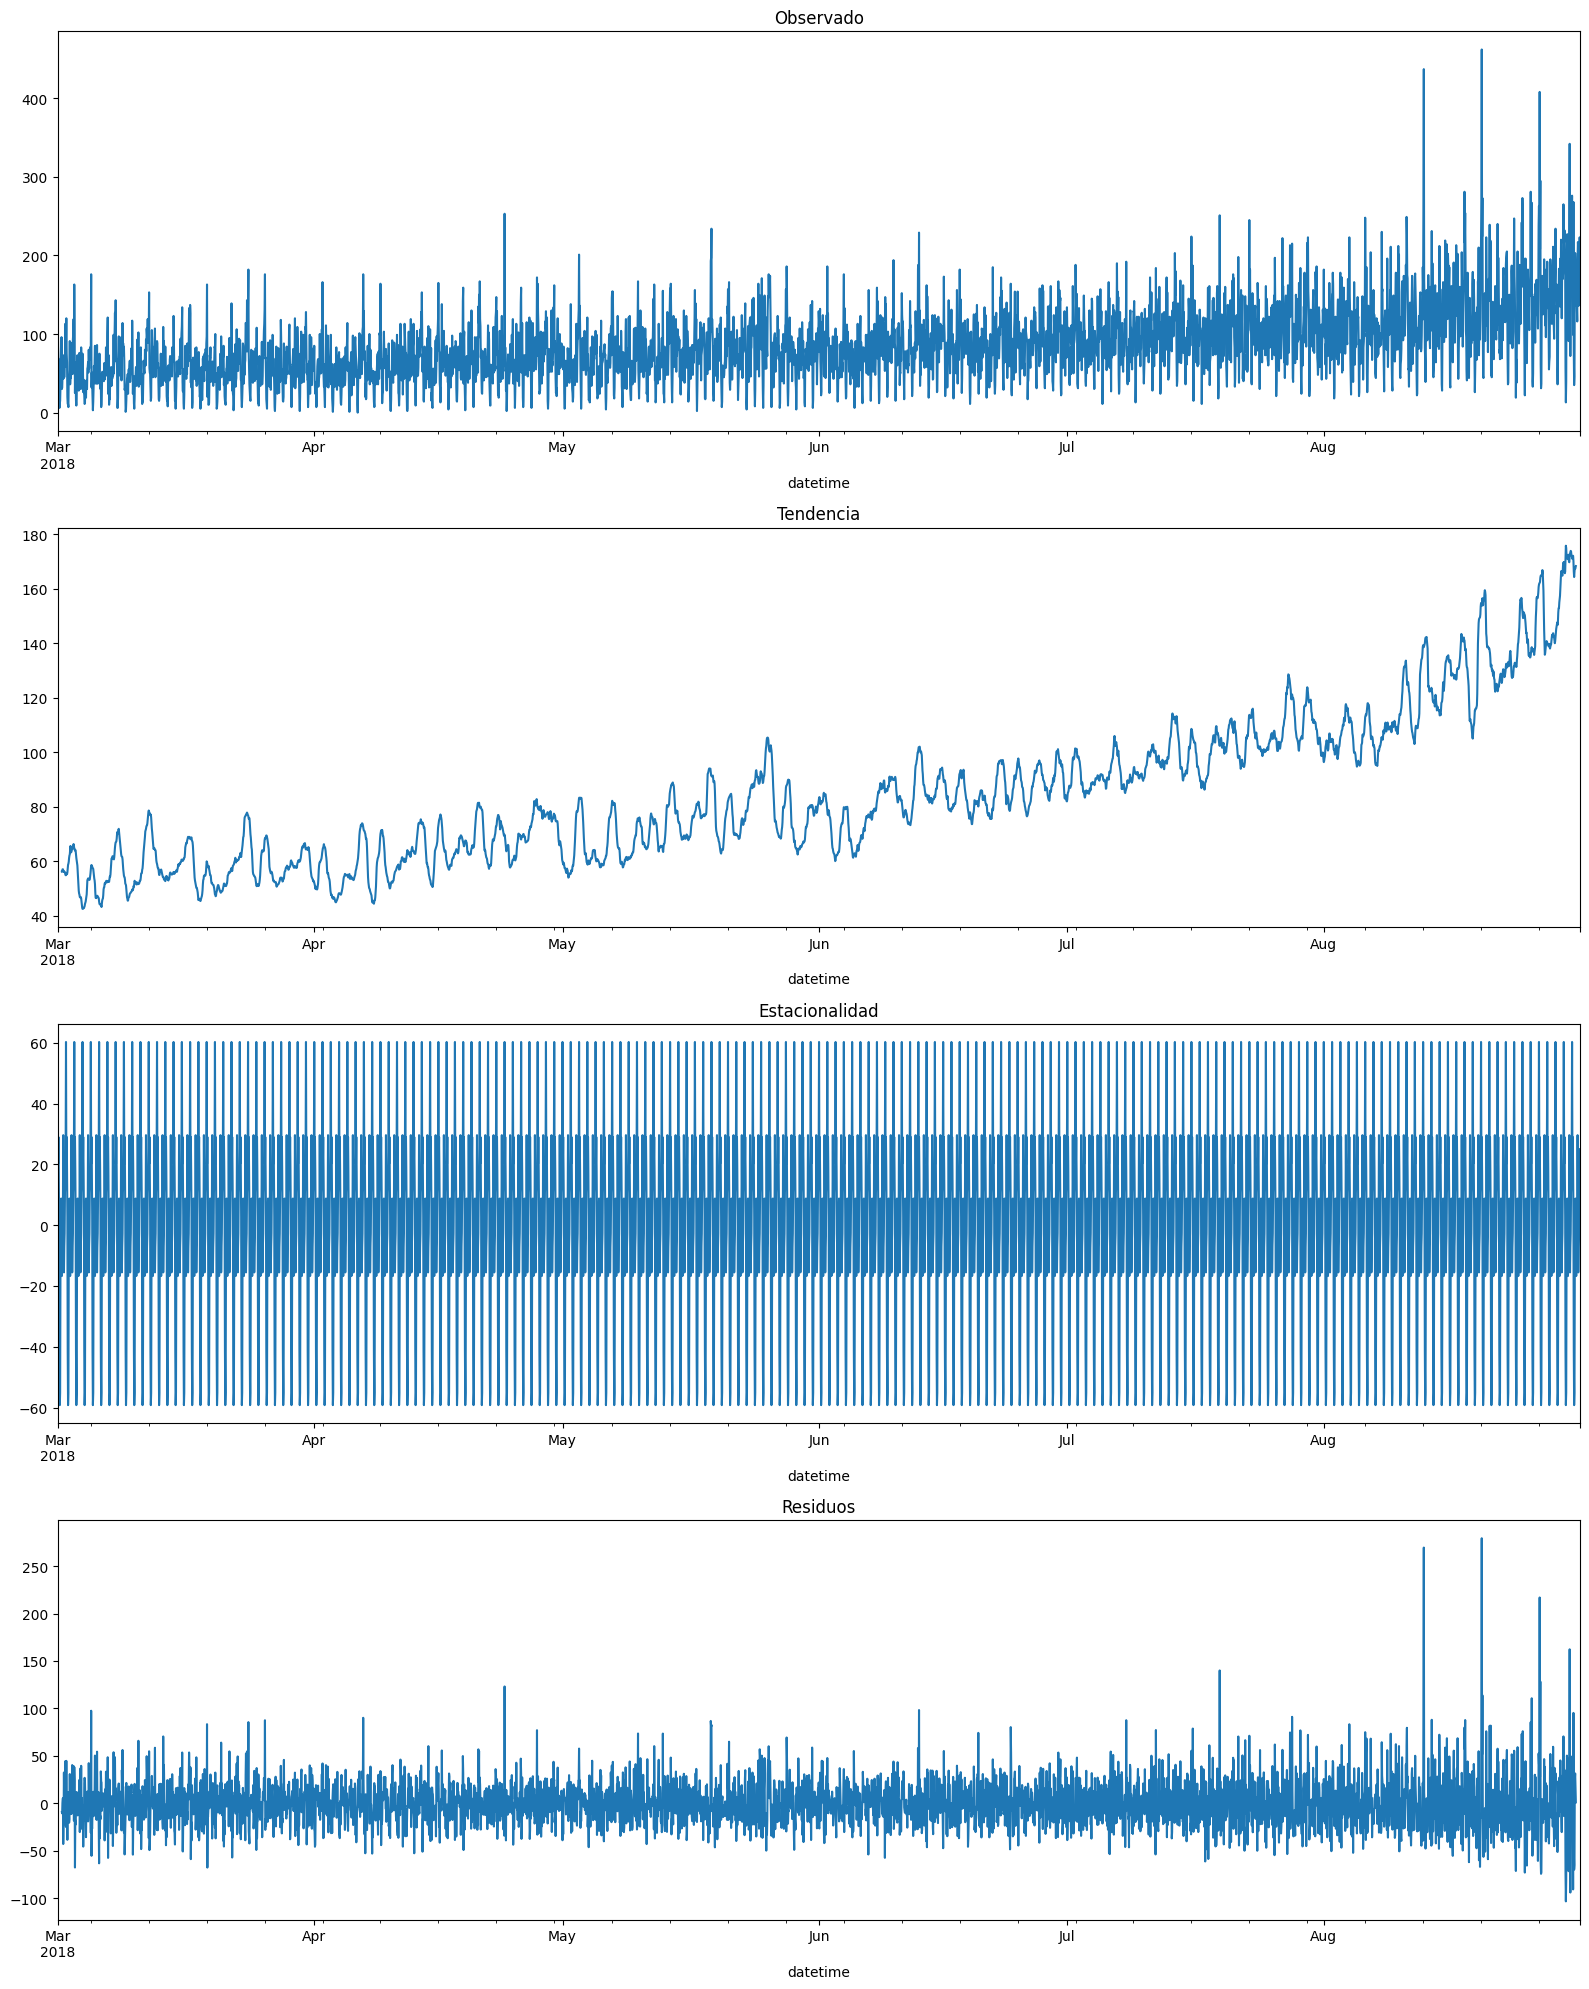

In [5]:
# Descomposición de datos
decomposed = seasonal_decompose(data['num_orders'], period=24)

# Grafícas de tendencia, estacionalidad y residuos
plt.figure(figsize=(16, 20))
plt.subplot(411)
decomposed.observed.plot(ax=plt.gca())
plt.title('Observado')
plt.subplot(412)
decomposed.trend.plot(ax=plt.gca())
plt.title('Tendencia')
plt.subplot(413)
decomposed.seasonal.plot(ax=plt.gca())
plt.title('Estacionalidad')
plt.subplot(414)
decomposed.resid.plot(ax=plt.gca())
plt.title('Residuos')

plt.tight_layout()
plt.show()

#### Observaciones
Una vez se ha 'fraccionado' los datos se determina lo siguiente:
- Se corrobora **la tendencia en el aumento de pedidos de taxi** en el periodo de tiempo analizado.
- Se observa una **estacionalidad marcada diariamente**, lo que indica que se tienen horas pico de solicitud de taxis al aeropuerto. Este dato nos será muy útil al momento de entrenar los modelos.

Para determinar la estacionalidad horaria en el pedido de taxis, se estudiará el comportamiento de pedidos en una semana.

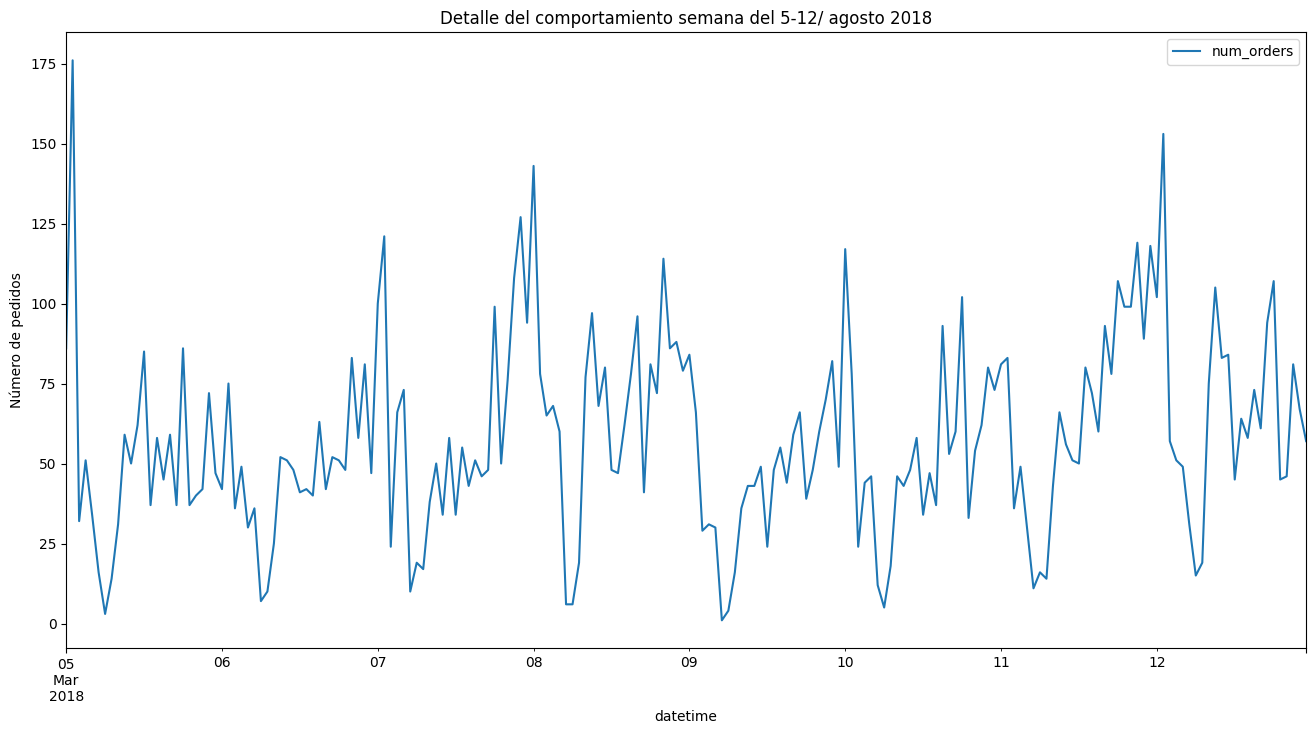

In [6]:
# Comportamiento semanal
data['2018-03-05':'2018-03-12'].plot(figsize=(16,8), title='Detalle del comportamiento semana del 5-12/ agosto 2018')
plt.ylabel('Número de pedidos')
plt.show()

#### Observaciones
Revisando el comportamiento de los datos en una semana se puede identificar que hay horas valle sobre las primeras horas del día donde los pedidos disminuyen considerablemente, y se tienen horas pico luego del mediodía donde los pedidos se incrementan notablemente.
Este es un comportamiento típico para viajes a un aeropuerto.

Se puede usar la media móvil para poder tener una mejor visión de la tendencia.

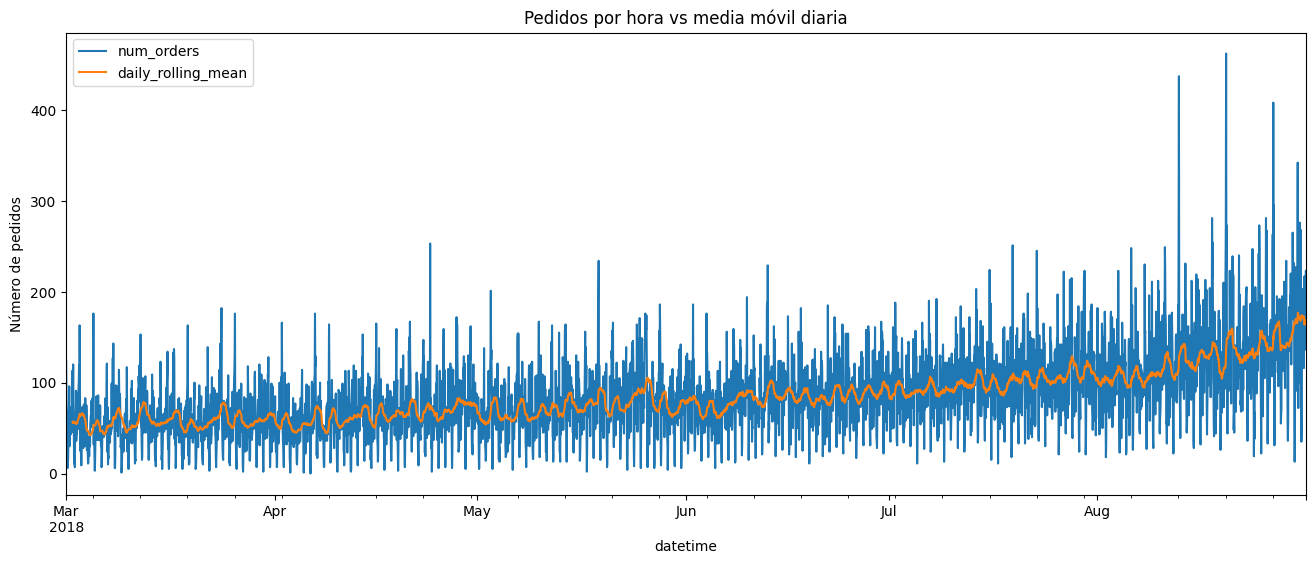

In [7]:
# Cálculo de media móvil diaria
data['daily_rolling_mean'] = data['num_orders'].rolling(24).mean()

#Comportamiento gráfico
data[['num_orders', 'daily_rolling_mean']].plot(figsize=(16, 6), title='Pedidos por hora vs media móvil diaria')
plt.ylabel('Número de pedidos')

plt.show()

#### Observaciones

Con la media móvil se puede visualizar mejor el incremento en el número de pedidos durante el periodo de tiempo disponible.
Esta tendencia y la estacionalidad diaria son factores clave en el entrenamiento de los modelos a entrenar para la determinación de pronósticos de pedidos de taxis.

## Formación

### Ingeniería de características
Para realizar la tarea de regresión solicitada, teniendo en cuenta la estacionalidad y tendencia de los datos, se deben formar las siguientes características:

- **Características de calendario:** separar por hora del día, dia de la semana y dia.
- **Rezagos:** vital teniendo en cuenta la estacionalidad diaria.
- **Media móvil:** tomando el promedio de las últimas N horas, con desplazamiento para controlar la fuga de información.

In [8]:
# Función para generar características
def make_features(data, max_lag, rolling_mean_size):

    data = data.copy()
    
    # Características de calendario
    data['hour'] = data.index.hour
    data['dayofweek'] = data.index.dayofweek
    data['day'] = data.index.day

    # Rezagos
    for lag in range(1, max_lag + 1):
        data[f'lag_{lag}'] = data['num_orders'].shift(lag)

    # Media móvil
    data['rolling_mean'] = data['num_orders'].shift().rolling(rolling_mean_size).mean()

    return data


In [9]:
# Generación del dataset previo a entrenamiento de modelos
data_features = make_features(data, 48, 24)

# Remoción columna 'daily_rolling_mean' y de datos NaN formados en la formación de 'rezagos'
data_features = data_features.drop('daily_rolling_mean', axis=1)
data_features = data_features.dropna()

data_features.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 4368 entries, 2018-03-03 00:00:00 to 2018-08-31 23:00:00
Freq: H
Data columns (total 53 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   num_orders    4368 non-null   int64  
 1   hour          4368 non-null   int64  
 2   dayofweek     4368 non-null   int64  
 3   day           4368 non-null   int64  
 4   lag_1         4368 non-null   float64
 5   lag_2         4368 non-null   float64
 6   lag_3         4368 non-null   float64
 7   lag_4         4368 non-null   float64
 8   lag_5         4368 non-null   float64
 9   lag_6         4368 non-null   float64
 10  lag_7         4368 non-null   float64
 11  lag_8         4368 non-null   float64
 12  lag_9         4368 non-null   float64
 13  lag_10        4368 non-null   float64
 14  lag_11        4368 non-null   float64
 15  lag_12        4368 non-null   float64
 16  lag_13        4368 non-null   float64
 17  lag_14        4368 non-null

#### Observaciones:
- La columna 'daily_rolling_mean' se utilizó para revisar como se comportaba la media movil respecto a los datos crudos y pudo retirarse sin afectar el modelo.
- Se toma como max_lag un valor de 48 unidades para cubrir 2 días de comportamiento de los pedidos de los taxis con adelanto de una hora, esto permitirá obtener un modelo mas robusto y sus predicciones tendrán mejores métricas.
- Se toma como rolling_mean_size un valor de 24 para tener en cuenta la estacionalidad horaria de solicitudes de taxis

In [10]:
# División conjuntos de entrenamiento y prueba, características y objetivo
train, test = train_test_split(data_features, shuffle=False, test_size=0.1)


features_train = train.drop(['num_orders'], axis=1)
target_train = train['num_orders']
features_test = test.drop(['num_orders'], axis=1)
target_test = test['num_orders']

# Revisión datos finales
print('Entrenamiento:', features_train.shape, 'desde', train.index.min(), 'hasta', train.index.max())
print('Prueba:       ', features_test.shape, 'desde', test.index.min(), 'hasta', test.index.max())


Entrenamiento: (3931, 52) desde 2018-03-03 00:00:00 hasta 2018-08-13 18:00:00
Prueba:        (437, 52) desde 2018-08-13 19:00:00 hasta 2018-08-31 23:00:00


#### Observaciones
Partiendo de un juego con 4368 observaciones se realiza la partición de datos de entrenamiento y prueba con 10% de los datos para prueba (437 observaciones), y se corrobora que los datos sigan el orden cronológico para evitar que una fuga de datos afecte el modelo entrenado al contar con datos conocidos.

De esta forma, los datos de entrenamiento van del 1 de marzo al 13 de agosto de 2018 a las 18:00 horas, y el conjunto de prueba va del 13 de agosto a las 19:00 horas hasta el 31 de agosto.

Ya con estos datos, y definiendo la columna 'num_orders' como objetivo de las regresiones, se puede iniciar a entrenar los modelos.

### Entrenamiento de modelos
Para el entrenamiento de modelos se desarrollará una función para la evaluación de modelos, de la misma forma en que se hizo en el proyecto del Sprint pasado. Luego se puede establecer el entrenamiento de diferentes modelos.
1. **Modelo Dummy:** de acuerdo a la teoría impartida, podemos tomar como primer pronóstico el dato de la hora inmediatamente anterior. Esto sirve como punto de partida y establece un criterio sobre el cual calificar los demas modelos.
2. **Modelo de Regresión lineal:** funciona como prueba de cordura para los otros modelos a desarrollar.
3. **Árbol de decisión:** se prueban profundidades de árbol de 4, 6, 8 y 10 unidades y se evalúa el RCEM para cada profundidad.
4. **Bosque aleatorio:** parra este modelo se prueban 3 combinaciones de número de árboles y profundidad: 50 árboles de profundidad 8, 100 árboles de profundidad 10 y 100 árboles de profundidad 12'.

In [11]:
# Modelo Dummy
dummy_rmse = mean_squared_error(target_test, features_test['lag_1']) ** 0.5
print(f'El RECM del modelo dummy es: {dummy_rmse:.2f}' )

El RECM del modelo dummy es: 59.02


In [14]:
# Función de evaluación de modelos

# Validación cruzada en series temporales con 5 particiones
tscv = TimeSeriesSplit(n_splits=5)
# Tabla vacia de almacenamiento de resultados
cv_results = []
def evaluate_cv(model, model_name, params=''):
    # Cálculo de métricas de evaluación
    scores = cross_val_score(model, features_train, target_train, cv=tscv, scoring='neg_root_mean_squared_error')

    rmse_cv = -scores.mean()
    print(f'{model_name} {params}: RECM promedio (CV) = {rmse_cv:.2f}')

    #Adición del resultado a la tabla
    cv_results.append({'Modelo': model_name, 'Hiperparámetros': params, 'RECM_CV': round(rmse_cv, 2)})
    return rmse_cv

In [15]:
# Regresión lineal
_ = evaluate_cv(LinearRegression(), 'Regresión lineal')

Regresión lineal : RECM promedio (CV) = 24.76


In [17]:
# Árbolde decisión
for depth in [4, 6, 8, 10]:
    evaluate_cv(DecisionTreeRegressor(max_depth=depth, random_state=rnd_stt), 'Árbol de decisión', params=f'(max_depth={depth})')

Árbol de decisión (max_depth=4): RECM promedio (CV) = 29.41
Árbol de decisión (max_depth=6): RECM promedio (CV) = 30.14
Árbol de decisión (max_depth=8): RECM promedio (CV) = 31.82
Árbol de decisión (max_depth=10): RECM promedio (CV) = 34.25


In [20]:
# Bosque aleatorio
for n_estimators, depth in [(50, 8), (100, 10), (100, 12)]:
    evaluate_cv(RandomForestRegressor(n_estimators=n_estimators, max_depth=depth, random_state=rnd_stt, n_jobs=-1), 'Bosque aleatorio', params=f'(n_estimators={n_estimators}, max_depth={depth})')

Bosque aleatorio (n_estimators=50, max_depth=8): RECM promedio (CV) = 24.86
Bosque aleatorio (n_estimators=100, max_depth=10): RECM promedio (CV) = 24.51
Bosque aleatorio (n_estimators=100, max_depth=12): RECM promedio (CV) = 24.40


In [21]:
# Unificación resultados
cv_results_df = pd.DataFrame(cv_results).sort_values('RECM_CV').reset_index(drop=True)
cv_results_df

,Modelo,Hiperparámetros,RECM_CV
0,Bosque aleatorio,"(n_estimators=100, max_depth=12)",24.40
1,Bosque aleatorio,"(n_estimators=100, max_depth=10)",24.51
2,Regresión lineal,,24.76
3,Bosque aleatorio,"(n_estimators=50, max_depth=8)",24.86
4,Árbol de decisión,(max_depth=4),29.41
5,Árbol de decisión,(max_depth=6),30.14
6,Árbol de decisión,(max_depth=8),31.82
7,Árbol de decisión,(max_depth=10),34.25


#### Observaciones
Se han definido las métricas para varios modelos de regresión a partir de los datos disponibles.
- Se parte de un modelo Dummy a partir del último dato de entrenamiento. Teniendo en cuenta la variabilidad que se tiene en la hora para la solicitud de taxis, se encuentra **un RECM de 59.02**, valor más alto que el esperado por un modelo de predicción pero que sirve como línea base.
- El modelo de regresión lineal muestra un **RECM de 24.76** valor por debajo del valor mínimo permitido, esto indica un buen modelo de regresión.
- Los modelos de árbol de decisión muestran una particularidad, si bien todos los datos se encuentran dentro del rango permitido, a medida que aumenta la profundidad del árbol, *también incrementa el RECM*. Esto muestra un sobreajuste de los datos, y se puede explicar por los rezagos implementados en el modelo. El mejor resultado para este modelo ocurre con **un árbol de profundidad 4, que presenta un RECM de 29.41**.
- Finalmente el Bosque aleatorio compensa este sobreajuste, y para una configuración de **100 árboles de profundidad 12, entrega un RECM de 24.40**, la cual es la mejor métrica obtenida en el estudio de los diferentes modelos.

*Con los resultados obtenidos en este paso, se tomarán el bosque aleatorio de 100 árboles de profundidad 12 y la regresión lineal como modelos para realizar las pruebas.*

## Prueba

In [23]:
# Modelos a entrenar
final_models = {'Regresión lineal': LinearRegression(), 'Bosque aleatorio (mejor configuración)': RandomForestRegressor(n_estimators=100, max_depth=12, random_state=rnd_stt, n_jobs=-1)}

#Tablas vacias
test_results = []
predictions = {}

for name, model in final_models.items():
    model.fit(features_train, target_train)
    pred_test = model.predict(features_test)
    predictions[name] = pred_test

    #Cálculo RECM
    rmse_test = mean_squared_error(target_test, pred_test) ** 0.5
    print(f'{name}: RECM para datos de prueba = {rmse_test:.2f}')
    # Adición a tabla de resultados
    test_results.append({'Modelo': name, 'RECM prueba': round(rmse_test, 2)})

# Adición RECM modelo Dummy
test_results.append({'Modelo': 'Dummy (referencia)', 'RECM prueba': round(dummy_rmse, 2)})
pd.DataFrame(test_results).sort_values('RECM prueba').reset_index(drop=True)

Regresión lineal: RECM para datos de prueba = 42.00
Bosque aleatorio (mejor configuración): RECM para datos de prueba = 41.39


,Modelo,RECM prueba
0,Bosque aleatorio (mejor configuración),41.39
1,Regresión lineal,42.00
2,Dummy (referencia),59.02


#### Observaciones
Se entrenaron los modelos que mostraron mejores métricas en la primera evaluación, la regresión lineal y el bosque aleatorio de 100 árboles de profundidad 12. los modelos entrenados se sometieron a la evaluación con los datos de prueba disponibles. Se evaluaron nuevamente la métrica de RECM para ambos modelos y se comparó con el RECM del modelo Dummy.

Se encuentra que el Bosque aleatorio sigue presentando los mejores resultados de predicción.
si bien el RECM en ambos modelos aumenta comparado con las métricas con los datos de entrenamiento, ambos modelos tienen un RECM menor a 48, lo cual indica que los modelos son confiables.

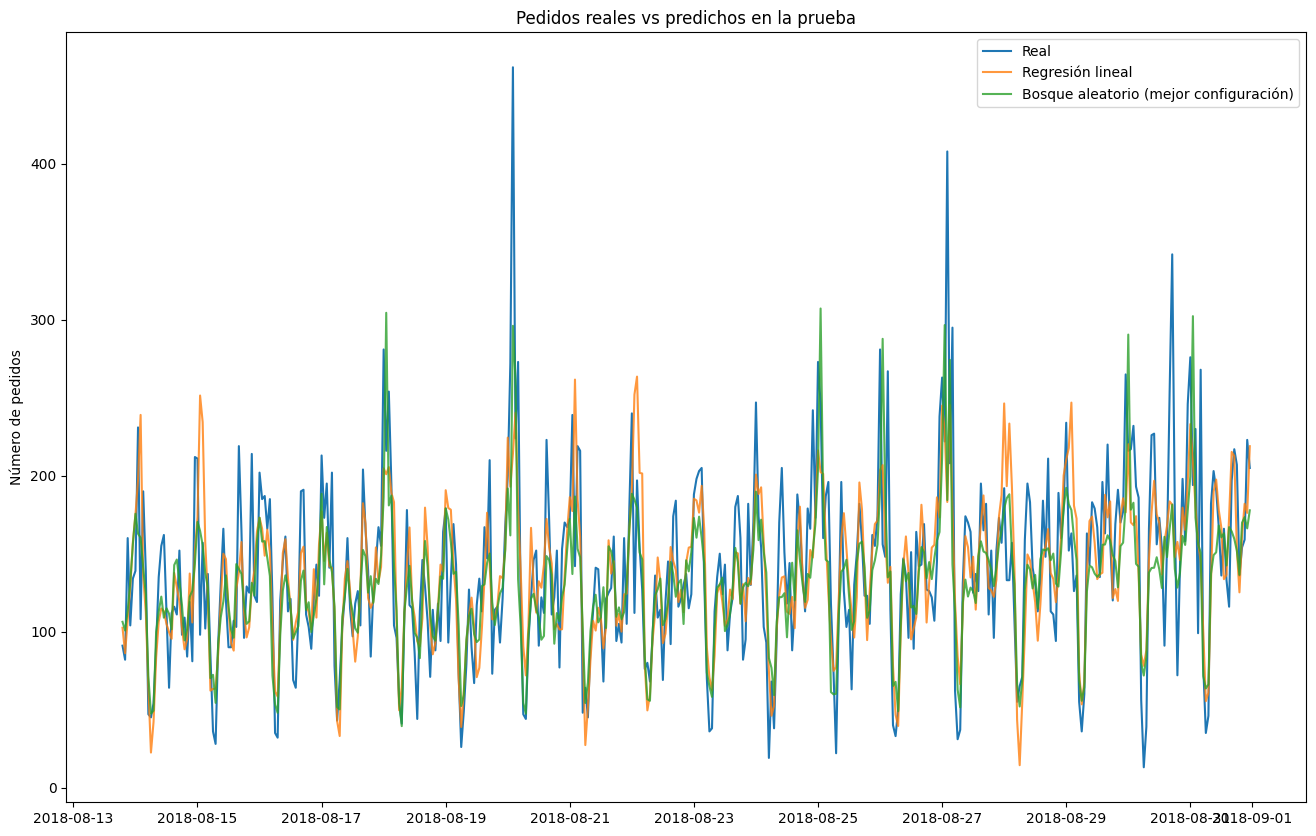

In [26]:
# Comportamiento gráfico de las predicciones
plt.figure(figsize=(16, 10))
plt.plot(target_test.index, target_test.values, label='Real', linewidth=1.5)
for name, pred in predictions.items():
    plt.plot(target_test.index, pred, label=name, alpha=0.8)
plt.legend()
plt.title('Pedidos reales vs predichos en la prueba')
plt.ylabel('Número de pedidos')
plt.show()

#### Observaciones
Al observar el comportamiento de las predicciones de los modelos de regresión lineal y bosque aleatorio y su comparación con los datos reales del conjunto de prueba, se encuentra una buena correlación de resultados, identificando los momentos pico y valle encontrados previamente.

## Conclusiones

- A partir de un juego de datos de número de pedidos de taxi al aeropuerto en un intérvalo de tiempo de 6 meses, se han entrenado métodos de regresión para la predicción de pedidos de taxi.
- Este conjunto de datos se sometió a tratamiento, se realizó un remuestreo para obtener valores de hora, se revisó la tendencia creciente de los datos y la estacionalidad en determinadas horas del día.
- A partir de este análisis, se realizó una ingeniería de características para obtener datos de dia, dia de la semana, hora, además de rezagos de 48 horas y con una media móvil de 24 horas, lo que permitiría obtener unos resultados robustos al momentos de realizar cualquier análisis.
- Se compararon métricas de RECM para varios modelos como regresión lineal, árbol de decisión y bosque aleatorio, los dos últimos, con varias configuraciones de hiperparámetros para evaluar los mejores resultados en un conjunto de entrenamiento.
- Se establecio un modelo Dummy obtenido a partir de resultados de la hora anterior para establecer una base de comparación de los modelos.
- Los 3 modelos analizados superaron esta barrera del modelo Dummy. El árbol de decisión presentó los resultados con mayor variación y por ello no se tuvo en cuenta para el entrenamiento y prueba con datos de prueba.
- Finalmente al entrenar los modelos y evaluar las métricas de calificación, se encuentra que **el modelo de Bosque aleatorio de 100 árboles de profundidad 12** presenta el mejor RECM para los datos de prueba. Este modelo se puede implementar para el pronótico de pedidos de taxi al aeropuerto. Por ser un modelo no lineal, tiene un margen para identificar relaciones adicionales en caso de sumar otras características como factores climáticos.


# Lista de revisión

- [x]  	
Jupyter Notebook está abierto.
- [x]  El código no tiene errores
- [x]  Las celdas con el código han sido colocadas en el orden de ejecución.
- [x]  	
Los datos han sido descargados y preparados.
- [x]  Se ha realizado el paso 2: los datos han sido analizados
- [x]  Se entrenó el modelo y se seleccionaron los hiperparámetros
- [x]  Se han evaluado los modelos. Se expuso una conclusión
- [x] La *RECM* para el conjunto de prueba no es más de 48